# CIFAKE：AI 生成图像检测

## 学习目标
1. SVM：实现 hinge loss 与线性 SVM 的小批量随机次梯度训练，用随机傅里叶特征近似 RBF 核
2. K-Means：实现 k-means++ 初始化与 Lloyd 迭代，用聚类做异常检测，实现 AUROC 指标
3. FFN：实现 MLP 及训练、验证、模型选择的完整流程
4. CNN：实现 CNN 与数据增强，比较优化器与正则化的效果

## CIFAKE

CIFAKE（Bird & Lotfi, 2023）包含 60,000 张 CIFAR-10 真实照片（`REAL`）和 60,000 张 Stable Diffusion v1.4 生成的同类别图像（`FAKE`），32×32 RGB。训练集 100,000 张，测试集 20,000 张，两类各半。任务是判断一张图片是照片还是生成图。标签：`0` 为 REAL，`1` 为 FAKE。

数据从 Kaggle 下载：[`birdy654/cifake-real-and-ai-generated-synthetic-images`](https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images)。解压到本作业同级的 `data/cifake/`：

```
data/cifake/
├── train/REAL/*.jpg   (50,000)
├── train/FAKE/*.jpg   (50,000)
├── test/REAL/*.jpg    (10,000)
└── test/FAKE/*.jpg    (10,000)
```

## Guidelines
- 在 `# ========== 开始编写代码 ==========` 和 `# ========== 结束编写代码 ==========` 之间完成实验代码。尽量都用 PyTorch 原生实现。

## Submission
- 运行完整、保留全部输出的本 notebook，与所有生成结果（图片，CSV）打包的压缩文件。需要填写完毕 Part 5 的所有问题。

In [3]:
import math, time, csv, copy, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
%matplotlib inline
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.io import read_image, ImageReadMode

print(torch.__version__, torchvision.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用设备: {device}")

SEED = 0
torch.manual_seed(SEED)
random.seed(SEED)

DATA_ROOT = Path("data/cifake")
OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)

N_TRAIN = None       # 神经网络使用的训练样本数，None 表示全部
N_CLASSIC = 20_000   # SVM / K-Means 使用的训练子集大小
VAL = 5_000          # 从训练集划出的验证集大小
EPOCHS = 10
BATCH = 256

results = []

def record(part, task, name, metric, value, seconds):
    results.append(dict(part=part, task=task, method=name, metric=metric, value=round(float(value), 4), seconds=round(seconds, 1)))
    print(f"[{part}/{task}] {name}: {metric} = {value:.4f}  ({seconds:.0f}s)")

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

2.15.0+cu132 0.29.2+cu132
使用设备: cuda


## Part 0: 数据准备

读取 CIFAKE 的全部 120,000 张图片，并缓存至 `data/cifake.pt`。图片张量的形状为 `[N, 3, 32, 32]`。

In [4]:
def load_split(split):
    xs, ys = [], []
    for label, name in ((0, "REAL"), (1, "FAKE")):
        files = sorted((DATA_ROOT / split / name).glob("*.jpg"))
        assert files, f"{DATA_ROOT / split / name} 下没有图片，请检查数据路径"
        with ThreadPoolExecutor(16) as pool:
            imgs = list(pool.map(lambda f: read_image(str(f), ImageReadMode.RGB), files))
        xs.append(torch.stack(imgs))
        ys.append(torch.full((len(imgs),), label))
    return torch.cat(xs), torch.cat(ys)

cache = DATA_ROOT.with_suffix(".pt")
if cache.exists():
    X_tr, y_tr, X_te, y_te = torch.load(cache)
else:
    t = time.time()
    X_tr, y_tr = load_split("train")
    X_te, y_te = load_split("test")
    torch.save((X_tr, y_tr, X_te, y_te), cache)
    print(f"读取完成，用时 {time.time() - t:.0f}s")

print("train:", tuple(X_tr.shape), X_tr.dtype, " 标签计数:", torch.bincount(y_tr).tolist())
print("test: ", tuple(X_te.shape), X_te.dtype, " 标签计数:", torch.bincount(y_te).tolist())

train: (100000, 3, 32, 32) torch.uint8  标签计数: [50000, 50000]
test:  (20000, 3, 32, 32) torch.uint8  标签计数: [10000, 10000]


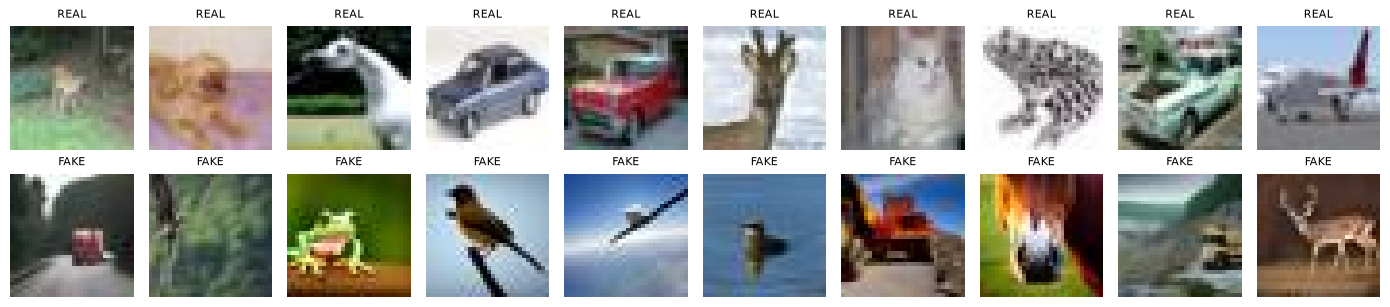

In [5]:
CLASS_NAMES = ("REAL", "FAKE")

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for row, label in enumerate((0, 1)):
    idx = torch.nonzero(y_tr == label).squeeze(1)
    idx = idx[torch.randperm(len(idx))[:10]]
    for ax, i in zip(axes[row], idx):
        ax.imshow(X_tr[i].permute(1, 2, 0))
        ax.set_axis_off()
        ax.set_title(CLASS_NAMES[label], fontsize=8)
savefig("samples")

### 预处理与数据划分

In [6]:
X_tr, y_tr, X_te, y_te = X_tr.to(device), y_tr.to(device), X_te.to(device), y_te.to(device)

MEAN = (X_tr.float() / 255).mean((0, 2, 3)).view(1, 3, 1, 1)
STD = (X_tr.float() / 255).std((0, 2, 3)).view(1, 3, 1, 1)

def normalize(X):
    return (X.float() / 255 - MEAN) / STD

T_tr, T_te = normalize(X_tr), normalize(X_te)
x_tr, x_te = T_tr.flatten(1), T_te.flatten(1)

perm = torch.randperm(len(T_tr), device=device)
val_idx, fit_idx = perm[:VAL], perm[VAL:]
if N_TRAIN is not None:
    fit_idx = fit_idx[:N_TRAIN]
sub = fit_idx[:N_CLASSIC]

print(f"训练 {len(fit_idx)} / 验证 {len(val_idx)} / 测试 {len(T_te)}；经典方法子集 {len(sub)}")
print("通道均值:", MEAN.flatten().tolist(), " 通道标准差:", STD.flatten().tolist())

训练 95000 / 验证 5000 / 测试 20000；经典方法子集 20000
通道均值: [0.4719941318035126, 0.46289345622062683, 0.41781532764434814]  通道标准差: [0.23757456243038177, 0.23742370307445526, 0.26595601439476013]


### 辅助函数：PCA

Part 1 与 Part 2 均需使用 PCA 降维，相关代码已给出。`pca_fit` 返回均值及前 `k` 个主方向（协方差矩阵按特征值降序排列的特征向量），`pca_transform` 计算投影，`pca_inverse` 由投影重构原始数据。

In [7]:
def pca_fit(X, k):
    mean = X.mean(0)
    cov = (X - mean).T @ (X - mean) / (len(X) - 1)
    evals, evecs = torch.linalg.eigh(cov)                 # 升序
    return mean, evecs[:, -k:].flip(1)                    # 取最大的 k 个并改为降序

def pca_transform(X, mean, V):
    return (X - mean) @ V

def pca_inverse(Z, mean, V):
    return Z @ V.T + mean

mean_sub, V_sub = pca_fit(x_tr[sub], 100)
z = pca_transform(x_te, mean_sub, V_sub)
print("PCA-100 测试集投影:", tuple(z.shape))
print("前 10 个主成分的方差:", [round(v, 2) for v in z.var(0)[:10].tolist()])

PCA-100 测试集投影: (20000, 100)
前 10 个主成分的方差: [751.19, 298.38, 195.8, 128.09, 122.99, 91.38, 83.97, 71.76, 66.64, 48.6]


## Part 1: 支持向量机

### 任务1.1：hinge loss

软间隔线性 SVM 的原问题如下（$y_i\in\{-1,+1\}$）：

$$
\min_{w,b}\ \frac{\lambda}{2}\|w\|^2 + \frac{1}{N}\sum_{i=1}^{N}\max\bigl(0,\ 1 - y_i(w^\top x_i + b)\bigr)
$$

其中第二项即 hinge loss。该函数在 $1 - y(w^\top x + b) = 0$ 处不可导，但无需特殊处理。使用 `torch.clamp` 实现前向计算后，自动微分给出的即为一个次梯度，可直接用于小批量随机次梯度下降。

本作业的标签取值为 `0/1`，使用前请通过 `y_pm = 2 * y - 1` 转换为 `±1`，即 REAL 对应 −1，FAKE 对应 +1。

In [8]:
# TODO: 任务1.1 - 实现合页损失
def hinge_loss(scores, y_pm):
    """
    合页损失（对 batch 取平均）

    Args:
        scores: torch.Tensor, shape [batch]，模型输出 w^T x + b
        y_pm:   torch.Tensor, shape [batch]，取值 -1 或 +1

    Returns:
        loss: 标量，mean(max(0, 1 - y * score))

    提示：
    1. 先计算 margin = y_pm * scores
    2. torch.clamp(1 - margin, min=0) 再取平均
    """
    # ========== 开始编写代码 ==========
    margin = y_pm * scores
    return torch.mean(torch.clamp(1 - margin, min = 0))

    # ========== 结束编写代码 ==========


# 测试你的实现
def test_hinge_loss():
    print("测试 hinge_loss")
    print("=" * 50)
    scores = torch.tensor([2.0, 0.5, -1.0, -0.2])
    y_pm = torch.tensor([1.0, 1.0, -1.0, 1.0])
    loss = hinge_loss(scores, y_pm)
    print(f"你的输出: {loss.item():.4f}  期望: 0.4250")
    print(f"是否一致: {torch.allclose(loss, torch.tensor(0.425))}")
    print(f"正确分类且在间隔外的样本损失为 0: {hinge_loss(torch.tensor([3.0]), torch.tensor([1.0])).item() == 0.0}")
    print("=" * 50)

test_hinge_loss()

测试 hinge_loss
你的输出: 0.4250  期望: 0.4250
是否一致: True
正确分类且在间隔外的样本损失为 0: True


### 任务1.2：线性 SVM 的训练与预测

请用 `nn.Linear(d, 1)` 表示 $w$ 与 $b$，并采用带动量的小批量随机次梯度下降最小化上述目标函数。训练数据为 `N_CLASSIC` 张图片经标准化后的像素，每张展平为 3072 维向量。

In [9]:
# TODO: 任务1.2 - 线性 SVM 的训练与预测
def train_linear_svm(X, y, lam=1e-4, epochs=20, lr=1e-3, batch_size=256, log=False):
    """
    使用带动量的小批量随机次梯度下降训练线性 SVM

    Args:
        X: torch.Tensor, shape [N, d]
        y: torch.Tensor, shape [N]，取值 0/1
        lam: L2 正则系数 λ

    Returns:
        model: nn.Linear(d, 1)

    提示：
    1. y_pm = 2 * y - 1
    2. 优化器使用 torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    3. 每个 epoch 用 torch.randperm 打乱样本，按 batch_size 切片
    4. 目标函数 = hinge_loss(model(xb).squeeze(1), yb) + 0.5 * lam * (model.weight ** 2).sum()
    """
    model = nn.Linear(X.shape[1], 1).to(X.device)
    # ========== 开始编写代码 ==========
    y_pm = 2 * y - 1
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    loss = 0
    for i in range(epochs):
        perm = torch.randperm(len(X), device=X.device)
        for start in range(0, len(X), batch_size):
            idx = perm[start : min(start + batch_size, len(X))]
            x_used = X[idx]
            y_used = y_pm[idx]
            loss = hinge_loss(model(x_used).squeeze(1), y_used) + 0.5 * lam * (model.weight ** 2).sum()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        if log:
            train_acc = svm_accuracy(model, X, y)
            print(f"[EPOCH#{i + 1}] Train Accuracy: {train_acc:.4f}")
    # ========== 结束编写代码 ==========
    return model

@torch.no_grad()
def svm_predict(model, X):
    """返回 0/1 预测标签，shape [N]"""
    # ========== 开始编写代码 ==========
    scores = model(X).squeeze(1)
    return (scores >= 0).long()
    # ========== 结束编写代码 ==========

@torch.no_grad()
def svm_accuracy(model, X, y):
    return (svm_predict(model, X) == y).float().mean().item()

# 一个小规模的线性可分测试
def test_linear_svm():
    print("测试 train_linear_svm")
    print("=" * 50)
    g = torch.Generator().manual_seed(0)
    Xs = torch.randn(400, 2, generator=g)
    ys = (Xs[:, 0] + Xs[:, 1] > 0).long()
    model = train_linear_svm(Xs.to(device), ys.to(device), lam=1e-3, epochs=30, lr=0.05)
    acc = svm_accuracy(model, Xs.to(device), ys.to(device))
    print(f"线性可分数据上的训练准确率: {acc:.4f}（应 > 0.97）")
    print("=" * 50)

test_linear_svm()

测试 train_linear_svm
线性可分数据上的训练准确率: 0.9850（应 > 0.97）


In [10]:
t = time.time()
svm_raw = train_linear_svm(x_tr[sub], y_tr[sub], log=True)
record("Part 1", "classification", "linear SVM (raw pixels)", "test_accuracy", svm_accuracy(svm_raw, x_te, y_te), time.time() - t)

[EPOCH#1] Train Accuracy: 0.6639
[EPOCH#2] Train Accuracy: 0.6740
[EPOCH#3] Train Accuracy: 0.6682
[EPOCH#4] Train Accuracy: 0.6787
[EPOCH#5] Train Accuracy: 0.6772
[EPOCH#6] Train Accuracy: 0.6825
[EPOCH#7] Train Accuracy: 0.6838
[EPOCH#8] Train Accuracy: 0.6869
[EPOCH#9] Train Accuracy: 0.6849
[EPOCH#10] Train Accuracy: 0.6922
[EPOCH#11] Train Accuracy: 0.6904
[EPOCH#12] Train Accuracy: 0.6933
[EPOCH#13] Train Accuracy: 0.6928
[EPOCH#14] Train Accuracy: 0.6828
[EPOCH#15] Train Accuracy: 0.6964
[EPOCH#16] Train Accuracy: 0.6951
[EPOCH#17] Train Accuracy: 0.6933
[EPOCH#18] Train Accuracy: 0.6867
[EPOCH#19] Train Accuracy: 0.6910
[EPOCH#20] Train Accuracy: 0.6889
[Part 1/classification] linear SVM (raw pixels): test_accuracy = 0.6610  (1s)


### 任务1.3：随机傅里叶特征近似 RBF 核

核 SVM 需要计算 $N\times N$ 的核矩阵，在十万量级的数据上无法存储。随机傅里叶特征（Random Fourier Features, RFF）为 RBF 核 $k(x, x') = \exp(-\gamma\|x - x'\|^2)$ 提供了一个显式的有限维近似：

$$
\phi(x) = \sqrt{\tfrac{2}{D}}\,\cos(Wx + b),\qquad W_{ij}\sim\mathcal N(0,\ 2\gamma),\quad b_j\sim U(0, 2\pi)
$$

根据 Bochner 定理，$\phi(x)^\top\phi(x') \approx k(x, x')$，且 $D$ 越大，近似越精确。因此，在 $\phi(x)$ 上训练线性 SVM（即任务 1.2 的 `train_linear_svm`）近似等价于训练 RBF 核 SVM。

本节先用 PCA 将像素降至 100 维，再映射到 $D = 8192$ 维。$\gamma$ 取 $1 / (d\cdot\mathrm{Var}[z])$，与 sklearn 中 `gamma="scale"` 的设定一致。注意 $\|\phi(x)\|\approx 1$，远小于 3072 维像素特征的范数，因此学习率需相应增大。

In [11]:
# TODO: 任务1.3 - 随机傅里叶特征
class RandomFourierFeatures:
    """
    RBF 核的随机傅里叶特征映射

    Args:
        d_in: 输入维度
        d_out: 特征维度 D
        gamma: RBF 核参数 γ

    提示：
    1. W 的形状为 [d_in, d_out]，元素 ~ N(0, 2γ)，即 torch.randn(...) * sqrt(2γ)
    2. b 的形状为 [d_out]，元素 ~ U(0, 2π)，即 torch.rand(...) * 2π
    3. __call__ 返回 sqrt(2/D) * cos(X @ W + b)
    """
    def __init__(self, d_in, d_out, gamma, device=device, seed=SEED):
        g = torch.Generator(device=device).manual_seed(seed)
        # ========== 开始编写代码 ==========
        self.W = torch.randn(d_in, d_out, generator=g, device=device) * math.sqrt(2 * gamma)
        self.b = torch.rand(d_out, generator=g, device=device) * 2 * torch.pi
        self.D = d_out
        # ========== 结束编写代码 ==========

    def __call__(self, X):
        # ========== 开始编写代码 ==========
        return math.sqrt(2 / self.D) * torch.cos(X @ self.W + self.b)
        # ========== 结束编写代码 ==========
        pass

# 测试：φ(x)·φ(x') 是否近似 exp(-γ||x - x'||²)
def test_rff():
    print("测试 RandomFourierFeatures")
    print("=" * 50)
    gamma = 0.5
    rff = RandomFourierFeatures(3, 20000, gamma)
    A = torch.randn(5, 3, device=device)
    B = torch.randn(5, 3, device=device)
    approx = (rff(A) * rff(B)).sum(1)
    exact = torch.exp(-gamma * ((A - B) ** 2).sum(1))
    print("近似核值:", [round(v, 3) for v in approx.tolist()])
    print("精确核值:", [round(v, 3) for v in exact.tolist()])
    print(f"最大误差: {(approx - exact).abs().max().item():.4f}（应 < 0.05）")
    print("=" * 50)

test_rff()

测试 RandomFourierFeatures


近似核值: [0.0, 0.715, 0.001, -0.001, 0.223]
精确核值: [0.004, 0.715, 0.0, 0.0, 0.223]
最大误差: 0.0039（应 < 0.05）


In [12]:
t = time.time()
mean_p, V_p = pca_fit(x_tr[sub], 100)
z_tr, z_te = pca_transform(x_tr[sub], mean_p, V_p), pca_transform(x_te, mean_p, V_p)
gamma = 1.0 / (z_tr.shape[1] * z_tr.var())
rff = RandomFourierFeatures(z_tr.shape[1], 8192, gamma.item())
svm_rff = train_linear_svm(rff(z_tr), y_tr[sub], lam=1e-5, epochs=30, lr=0.3)
record("Part 1", "classification", "PCA-100 + RFF-8192 + linear SVM (~ RBF SVM)", "test_accuracy", svm_accuracy(svm_rff, rff(z_te), y_te), time.time() - t)

[Part 1/classification] PCA-100 + RFF-8192 + linear SVM (~ RBF SVM): test_accuracy = 0.7847  (2s)


## Part 2: K-Means 聚类与异常检测

### 任务2.1：实现 K-Means

K-Means 的目标是最小化各样本到其所属簇中心的平方距离之和：

$$
\min_{C,\,\mu}\ \sum_{k=1}^{K}\sum_{x_i\in C_k}\|x_i - \mu_k\|^2
$$

Lloyd 算法交替执行两步直至收敛，首先将每个样本分配到最近的中心，然后将每个中心更新为簇内样本的均值。初始中心采用 k-means++ 选取。第一个中心随机选择，其后每个中心以样本到最近已有中心的距离平方为权重进行抽样，从而使初始中心彼此分散。

In [13]:
# TODO: 任务2.1 - 实现 k-means++ 初始化与 Lloyd 迭代
def kmeans_pp_init(X, K, generator):
    """
    k-means++ 初始化

    Args:
        X: torch.Tensor, shape [N, d]
        K: 簇数
        generator: torch.Generator，用于随机抽样

    Returns:
        centroids: torch.Tensor, shape [K, d]

    提示：
    1. 第一个中心：torch.randint(len(X), (1,), generator=generator, device=X.device)
    2. 之后每个中心：d2 = 到已有中心的最小距离平方（torch.cdist(X, centroids).min(1).values ** 2），
       按 d2 / d2.sum() 的概率用 torch.multinomial 抽取一个样本
    """
    # ========== 开始编写代码 ==========
    d = X.shape[1]
    centroids = torch.empty((K, d), device=X.device)
    first_index = torch.randint(len(X), (1,), generator=generator, device=X.device)
    centroids[0] = X[first_index]

    for i in range(1, K):
        d2 = torch.cdist(X, centroids[:i]).min(1).values ** 2
        probs = d2 / d2.sum()
        next_index = torch.multinomial(probs, num_samples=1, generator=generator)
        centroids[i] = X[next_index]

    return centroids
    # ========== 结束编写代码 ==========
    pass


def kmeans(X, K, iters=100, seed=SEED):
    """
    Lloyd 算法

    Args:
        X: torch.Tensor, shape [N, d]
        K: 簇数
        iters: 最大迭代次数

    Returns:
        centroids: torch.Tensor, shape [K, d]
        assign: torch.LongTensor, shape [N]，每个样本所属的簇

    提示：
    1. 分配：torch.cdist(X, centroids).argmin(1)
    2. 更新：用 torch.zeros(K, d).index_add_(0, assign, X) 累加，再除以 torch.bincount(assign, minlength=K)；
       空簇（计数为 0）保留原中心
    3. 中心不再变化（torch.allclose）则提前结束
    """
    generator = torch.Generator(device=X.device).manual_seed(seed)
    centroids = kmeans_pp_init(X, K, generator)
    # ========== 开始编写代码 ==========
    N = X.shape[0]
    d = X.shape[1]
    assign = torch.empty((N,), dtype=torch.long, device=X.device)
    for i in range(iters):
        assign = torch.cdist(X, centroids).argmin(1)  # Assignment

        sums = torch.zeros(K, d, device=X.device, dtype=X.dtype)
        sums.index_add_(0, assign, X)

        counts = torch.bincount(assign, minlength=K)
        new_centroids = centroids.clone()
        nonempty = counts > 0

        new_centroids[nonempty] = (sums[nonempty] / counts[nonempty].unsqueeze(1))
        converged = torch.allclose(centroids, new_centroids)

        centroids = new_centroids                     # Update
        if converged:
            break

    assign = torch.cdist(X, centroids).argmin(1)
    # ========== 结束编写代码 ==========
    return centroids, assign

# 测试：三个分得很开的高斯簇
def test_kmeans():
    print("测试 kmeans")
    print("=" * 50)
    g = torch.Generator().manual_seed(0)
    centers = torch.tensor([[0.0, 0.0], [8.0, 0.0], [0.0, 8.0]])
    labels = torch.arange(3).repeat_interleave(200)
    pts = (centers[labels] + torch.randn(600, 2, generator=g)).to(device)
    centroids, assign = kmeans(pts, 3)
    purity = sum(torch.bincount(labels.to(device)[assign == k], minlength=3).max().item() for k in range(3)) / 600
    print(f"簇中心:\n{centroids.cpu()}")
    print(f"簇纯度: {purity:.3f}（应 > 0.95）")
    print("=" * 50)

test_kmeans()

测试 kmeans
簇中心:
tensor([[-0.2418,  8.0917],
        [ 8.0748,  0.0609],
        [ 0.0883,  0.0366]])
簇纯度: 1.000（应 > 0.95）


### 任务2.2：聚类能分开真图和假图吗

在 PCA-50 空间中将训练子集聚为 $K=2$ 类，并计算簇标签与真伪标签的一致率。由于簇编号与类别之间的对应关系是任意的，取两种对应方式中较高的一致率。

下方绘制了每个簇的样本，请观察聚类实际依据何种特征划分图片。这里的 cluster-label agreement 是带标签的外部聚类评估，不等同于监督分类准确率。

[Part 2/clustering] 2-means on PCA-50, cluster/label agreement: cluster_label_agreement = 0.5899  (0s)


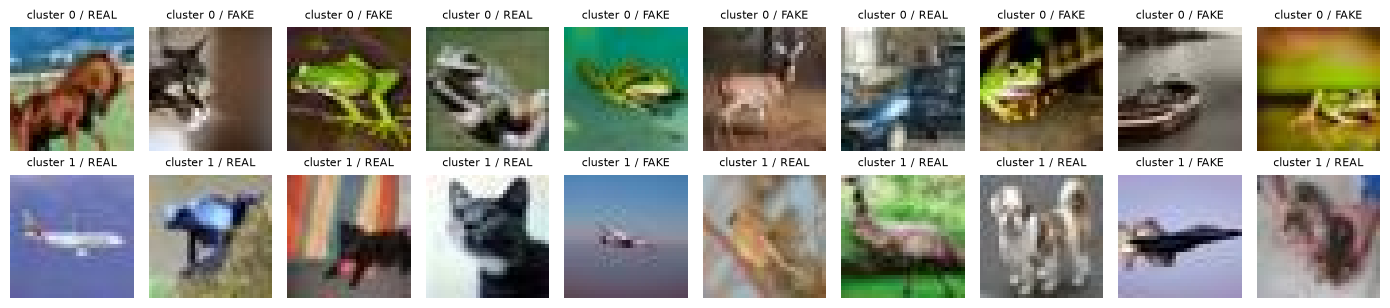

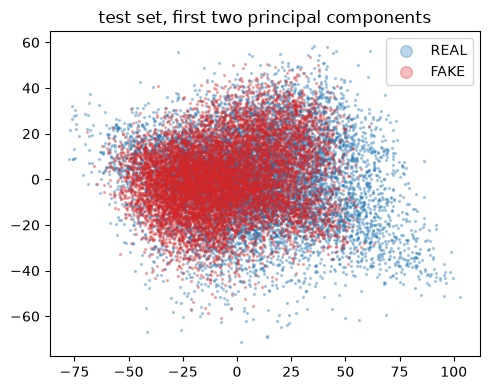

In [14]:
t = time.time()
mean_50, V_50 = pca_fit(x_tr[sub], 50)
z50_tr, z50_te = pca_transform(x_tr[sub], mean_50, V_50), pca_transform(x_te, mean_50, V_50)
centroids2, _ = kmeans(z50_tr, 2)
pred2 = torch.cdist(z50_te, centroids2).argmin(1)
agreement = max((pred2 == y_te).float().mean().item(), (pred2 != y_te).float().mean().item())
record("Part 2", "clustering", "2-means on PCA-50, cluster/label agreement", "cluster_label_agreement", agreement, time.time() - t)

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for row in range(2):
    idx = torch.nonzero(pred2 == row).squeeze(1)
    idx = idx[torch.randperm(len(idx))[:10]]
    for ax, i in zip(axes[row], idx):
        ax.imshow(X_te[i].permute(1, 2, 0).cpu())
        ax.set_axis_off()
        ax.set_title(f"cluster {row} / {CLASS_NAMES[y_te[i]]}", fontsize=8)
savefig("kmeans_clusters")

fig, ax = plt.subplots(figsize=(5, 4))
for label, color in ((0, "tab:blue"), (1, "tab:red")):
    m = y_te == label
    ax.scatter(z50_te[m, 0].cpu(), z50_te[m, 1].cpu(), s=2, alpha=0.3, c=color, label=CLASS_NAMES[label])
ax.set_title("test set, first two principal components")
ax.legend(markerscale=6)
savefig("pca_scatter")

### 任务2.3：异常检测与 AUROC

本任务仅使用真实照片进行训练，并将生成图像视为异常。在 PCA-100 空间中对真实照片做 $K=64$ 的 K-Means，以测试图片到最近簇中心的距离作为异常分数，距离越大，说明该图片越可能是生成图像。

异常分数本身没有确定的判定阈值，因此采用 AUROC 进行评价。AUROC 等于随机抽取一张生成图像和一张真实照片时，前者分数高于后者的概率。随机打分的 AUROC 为 0.5，完全正确的排序为 1。请按以下基于排名的公式实现 AUROC：

$$
\mathrm{AUROC} = \frac{\sum_{i\in\text{正类}} r_i - n_+(n_++1)/2}{n_+\,n_-}
$$

其中 $r_i$ 为全部分数升序排列后的排名（从 1 开始），正类为 FAKE。分数并列的情况可不作处理。下方同时给出以 PCA 重构误差作为异常分数的结果，以作对比。

In [15]:
# TODO: 任务2.3 - 实现 AUROC
def auroc(scores, labels):
    """
    Args:
        scores: torch.Tensor, shape [N]，异常分数，越大越可能是正类
        labels: torch.Tensor, shape [N]，取值 0/1，1 为正类

    Returns:
        float

    提示：
    1. order = scores.argsort()；排名 ranks[order] = 1..N
    2. 代入上面的公式
    """
    # ========== 开始编写代码 ==========
    N = len(scores)
    order = scores.argsort()
    ranks = torch.empty(N, dtype=torch.float64, device=scores.device)
    ranks[order] = torch.arange(1, N + 1, dtype=torch.float64, device=scores.device)

    n_plus = (labels == 1).sum().item()
    n_minus = (labels == 0).sum().item()

    # 实际中不可能出现
    if n_plus == 0 or n_minus == 0:
        raise ValueError("AUROC requires both positive and negative samples")

    rank_sum = ranks[labels == 1].sum()
    auc = (rank_sum - n_plus * (n_plus + 1) / 2) / (n_plus * n_minus)
    return auc.item()
    # ========== 结束编写代码 ==========
    pass

def test_auroc():
    print("测试 auroc")
    print("=" * 50)
    s = torch.tensor([0.1, 0.4, 0.35, 0.8])
    l = torch.tensor([0, 0, 1, 1])
    print(f"你的输出: {auroc(s, l):.4f}  期望: 0.7500")
    print(f"完美排序: {auroc(torch.tensor([0.1, 0.2, 0.9, 0.95]), l):.4f}  期望: 1.0000")
    print(f"完全反序: {auroc(torch.tensor([0.9, 0.95, 0.1, 0.2]), l):.4f}  期望: 0.0000")
    print("=" * 50)

test_auroc()

测试 auroc
你的输出: 0.7500  期望: 0.7500
完美排序: 1.0000  期望: 1.0000
完全反序: 0.0000  期望: 0.0000


[Part 2/anomaly_detection] K-Means(64) centroid distance, REAL only: test_auroc = 0.5701  (0s)
[Part 2/anomaly_detection] PCA-100 reconstruction error, REAL only: test_auroc = 0.6652  (0s)


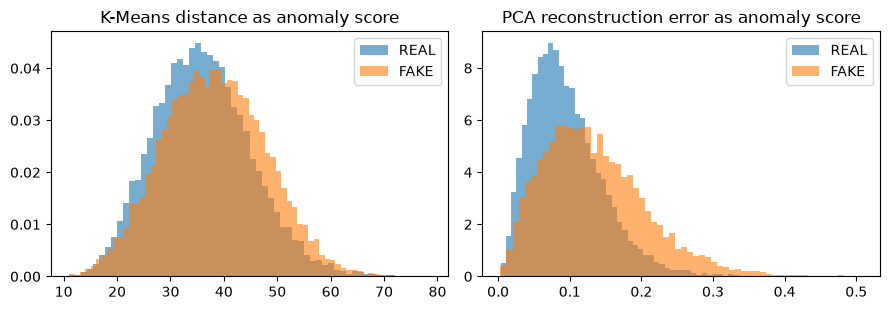

In [16]:
real_idx = fit_idx[y_tr[fit_idx] == 0]
t = time.time()
mean_r, V_r = pca_fit(x_tr[real_idx], 100)
zr_tr, zr_te = pca_transform(x_tr[real_idx], mean_r, V_r), pca_transform(x_te, mean_r, V_r)
centroids64, _ = kmeans(zr_tr, 64)
score_km = torch.cdist(zr_te, centroids64).min(1).values
record("Part 2", "anomaly_detection", "K-Means(64) centroid distance, REAL only", "test_auroc", auroc(score_km, y_te), time.time() - t)

t = time.time()
score_pca = ((x_te - pca_inverse(zr_te, mean_r, V_r)) ** 2).mean(1)
record("Part 2", "anomaly_detection", "PCA-100 reconstruction error, REAL only", "test_auroc", auroc(score_pca, y_te), time.time() - t)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (score, name) in zip(axes, ((score_km, "K-Means distance"), (score_pca, "PCA reconstruction error"))):
    for label in (0, 1):
        ax.hist(score[y_te == label].cpu().tolist(), 60, alpha=0.6, density=True, label=CLASS_NAMES[label])
    ax.set_title(f"{name} as anomaly score")
    ax.legend()
savefig("anomaly_scores")

## Part 3: 前馈神经网络

### 辅助函数：小批量迭代与评估（已给出）

此后所有模型均采用相同的训练流程：使用交叉熵损失进行小批量训练，每个 epoch 结束后在干净的训练集和验证集上分别记录 loss 与 accuracy，保留验证准确率最高一轮的参数，最后在测试集上仅评估一次。

In [17]:
def iterate_minibatches(index, batch_size, shuffle=True):
    if shuffle:
        index = index[torch.randperm(len(index), device=index.device)]
    for i in range(0, len(index), batch_size):
        yield index[i:i + batch_size]

@torch.no_grad()
def evaluate_metrics(model, X, y, batch_size=2048):
    """在干净的输入上返回平均交叉熵和准确率。"""
    model.eval()
    total_loss, correct = 0.0, 0
    for idx in iterate_minibatches(torch.arange(len(X), device=X.device), batch_size, shuffle=False):
        logits = model(X[idx])
        total_loss += F.cross_entropy(logits, y[idx], reduction="sum").item()
        correct += (logits.argmax(1) == y[idx]).sum().item()
    return total_loss / len(X), correct / len(X)

@torch.no_grad()
def evaluate(model, X, y, batch_size=2048):
    return evaluate_metrics(model, X, y, batch_size)[1]

def count_params(model):
    return sum(p.numel() for p in model.parameters())

### 任务3.1：MLP

输入为展平后的 3072 维向量，网络由若干 `Linear + ReLU` 层构成，最后一层输出 2 个 logits。

In [18]:
# TODO: 任务3.1 - 实现 MLP
class MLP(nn.Module):
    """
    多层感知机

    Args:
        hidden: 各隐藏层宽度，如 (512, 256)
        num_classes: 输出类别数

    提示：
    1. 先 nn.Flatten()，再依次 nn.Linear(in, h) + nn.ReLU()，最后 nn.Linear(h_last, num_classes)
    2. 用 nn.Sequential 组织各层
    """
    def __init__(self, hidden=(512, 256), num_classes=2):
        super().__init__()
        # ========== 开始编写代码 ==========
        layers = [nn.Flatten()]
        dimension = 3 * 32 * 32
        for width in hidden:
            layers.append(nn.Linear(dimension, width))
            layers.append(nn.ReLU())
            dimension = width

        layers.append(nn.Linear(dimension, num_classes))
        self.net = nn.Sequential(*layers)
        # ========== 结束编写代码 ==========

    def forward(self, x):
        # ========== 开始编写代码 ==========
        return self.net(x)


        # ========== 结束编写代码 ==========
        pass

# 测试
model = MLP((512, 256)).to(device)
out = model(T_tr[:4])
print(f"输出 shape: {tuple(out.shape)}（应为 (4, 2)）")
print(f"参数量: {count_params(model):,}（应为 1,705,218）")

输出 shape: (4, 2)（应为 (4, 2)）
参数量: 1,705,218（应为 1,705,218）


### 任务3.2：训练函数

请实现完整的训练循环。

In [19]:
# TODO: 任务3.2 - 实现训练函数
def train_model(model, X, y, X_val, y_val, epochs=EPOCHS, lr=1e-3, optimizer="adamw", batch_size=BATCH, augment=None, log=True):
    """
    Args:
        model: nn.Module
        X, y: 训练数据与标签
        X_val, y_val: 验证数据与标签
        optimizer: "adamw" 或 "sgd"
        augment: 对每个 batch 的输入做数据增强的函数，None 表示不增强

    Returns:
        history: dict，包含 train/val loss 与 train/val accuracy（list）
        训练结束后 model 恢复为验证准确率最高一轮的参数

    提示：
    1. adamw: torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=5e-4)
       sgd:   torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    2. 调度器: torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * ceil(N / batch_size))
    3. 每个 batch: 前向 → F.cross_entropy → zero_grad → backward → opt.step() → scheduler.step()
    4. 用 copy.deepcopy(model.state_dict()) 保存最优参数
    """
    model = model.to(device)
    # ========== 开始编写代码 ==========
    N = X.shape[0]
    if optimizer == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=5e-4)
    elif optimizer == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    else:
        raise RuntimeError("Unknown optimizer. Only ""adamw"" and ""sgd"" are supported.")

    scheduler = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * math.ceil(N / batch_size))
    # ========== 结束编写代码 ==========
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state = -1.0, None
    index = torch.arange(len(X), device=X.device)
    for epoch in range(epochs):
        model.train()
        for idx in iterate_minibatches(index, batch_size):
            xb, yb = X[idx], y[idx]
            if augment is not None:
                xb = augment(xb)
            # ========== 开始编写代码 ==========
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            
            opt.zero_grad()
            loss.backward()
            opt.step()
            scheduler.step()
            # ========== 结束编写代码 ==========
        train_loss, train_acc = evaluate_metrics(model, X, y)
        val_loss, val_acc = evaluate_metrics(model, X_val, y_val)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if val_acc > best_acc:
            best_acc, best_state = val_acc, copy.deepcopy(model.state_dict())
        if log:
            print(f"epoch {epoch + 1:2d}  train loss {train_loss:.4f}  val loss {val_loss:.4f}  train acc {train_acc:.4f}  val acc {val_acc:.4f}")
    model.load_state_dict(best_state)
    return history

def run_experiment(part, name, model, epochs=EPOCHS, log=True, **kw):
    """训练 → 在验证集上选最优 epoch → 测试集评价一次 → 记录"""
    t = time.time()
    history = train_model(model, T_tr[fit_idx], y_tr[fit_idx], T_tr[val_idx], y_tr[val_idx], epochs=epochs, log=log, **kw)
    record(part, "classification", name, "test_accuracy", evaluate(model, T_te, y_te), time.time() - t)
    return history

def plot_histories(histories, name):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for label, h in histories.items():
        axes[0].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], marker="o", ms=3, label=label)
        axes[0].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], marker="o", ms=3, label=f"{label} val")
        axes[1].plot(range(1, len(h["train_acc"]) + 1), h["train_acc"], marker="o", ms=3, label=f"{label} train")
        axes[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], marker="o", ms=3, linestyle="--", label=f"{label} val")
    axes[0].set_title("cross-entropy loss"); axes[1].set_title("accuracy")
    axes[0].set_ylabel("loss"); axes[1].set_ylabel("accuracy")
    for ax in axes:
        ax.set_xlabel("epoch"); ax.grid(True); ax.legend(fontsize=8)
    savefig(name)

# 快速测试：少量数据跑 2 个 epoch，损失应下降
small = fit_idx[:2048]
h = train_model(MLP((128,)), T_tr[small], y_tr[small], T_tr[val_idx], y_tr[val_idx], epochs=2, log=True)
print(f"损失下降: {h['train_loss'][-1] < h['train_loss'][0]}")

epoch  1  train loss 0.5872  val loss 0.6248  train acc 0.6792  val acc 0.6536
epoch  2  train loss 0.5261  val loss 0.6015  train acc 0.7231  val acc 0.6734
损失下降: True


### 任务3.3：训练 MLP，比较网络规模

下方代码训练三种规模的 MLP。请比较它们的训练/验证损失与训练/验证准确率，观察其随网络规模的变化。


MLP (256,)，参数量 787,202
epoch  1  train loss 0.4649  val loss 0.4807  train acc 0.7750  val acc 0.7626
epoch  2  train loss 0.4741  val loss 0.5023  train acc 0.7739  val acc 0.7636
epoch  3  train loss 0.4207  val loss 0.4562  train acc 0.8015  val acc 0.7794
epoch  4  train loss 0.4163  val loss 0.4663  train acc 0.8080  val acc 0.7798
epoch  5  train loss 0.3980  val loss 0.4620  train acc 0.8188  val acc 0.7874
epoch  6  train loss 0.3321  val loss 0.4099  train acc 0.8546  val acc 0.8140
epoch  7  train loss 0.3013  val loss 0.3997  train acc 0.8700  val acc 0.8204
epoch  8  train loss 0.2724  val loss 0.3928  train acc 0.8863  val acc 0.8260
epoch  9  train loss 0.2493  val loss 0.3810  train acc 0.8993  val acc 0.8330
epoch 10  train loss 0.2440  val loss 0.3787  train acc 0.9021  val acc 0.8356
[Part 3/classification] MLP (256,): test_accuracy = 0.8351  (3s)

MLP (512, 256)，参数量 1,705,218
epoch  1  train loss 0.4796  val loss 0.4984  train acc 0.7623  val acc 0.7532
epoch  2  tr

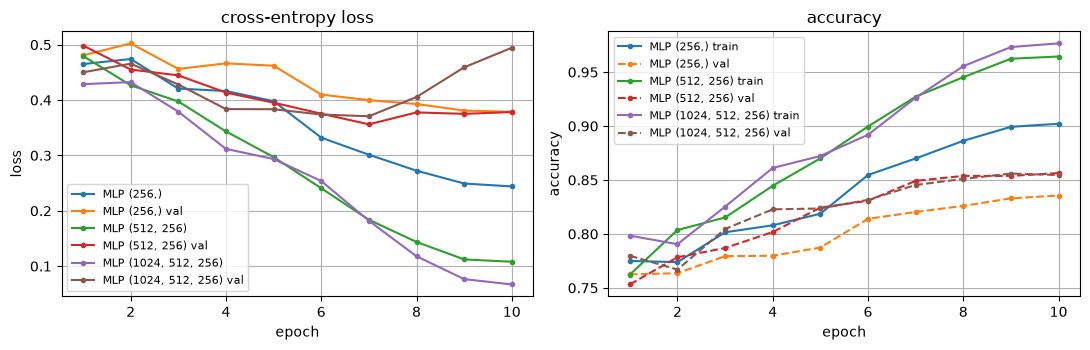

In [20]:
histories = {}
for hidden in ((256,), (512, 256), (1024, 512, 256)):
    name = f"MLP {hidden}"
    print(f"\n{name}，参数量 {count_params(MLP(hidden)):,}")
    histories[name] = run_experiment("Part 3", name, MLP(hidden))
h_mlp = histories["MLP (512, 256)"]
plot_histories(histories, "mlp_curves")

## Part 4: 卷积神经网络

### 任务4.1：CNN

In [21]:
# TODO: 任务4.1 - 实现 CNN
class CNN(nn.Module):
    """
    Args:
        channels: 三个卷积块的输出通道数
        use_bn: 是否在每个卷积后加 BatchNorm2d
        dropout: 分类头的 dropout 概率

    提示：
    1. 每个卷积块：nn.Conv2d(c_in, c_out, 3, padding=1), (nn.BatchNorm2d(c_out)), nn.ReLU(), nn.MaxPool2d(2)
    2. 分类头：nn.Flatten(), nn.Dropout(p), nn.Linear(c_last * 4 * 4, 256), nn.ReLU(), nn.Dropout(p), nn.Linear(256, num_classes)
    """
    def __init__(self, channels=(32, 64, 128), use_bn=False, dropout=0.0, num_classes=2):
        super().__init__()
        # ========== 开始编写代码 ==========
        c_in = 3
        layers: list[nn.Module] = []

        for c_out in channels:
            layers.append(nn.Conv2d(c_in, c_out, 3, padding=1))
            if use_bn:
                layers.append(nn.BatchNorm2d(c_out))
            layers.append(nn.ReLU())
            layers.append(nn.MaxPool2d(2))
            c_in = c_out

        self.net = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(channels[-1] * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )
        # ========== 结束编写代码 ==========

    def forward(self, x):
        # ========== 开始编写代码 ==========
        net_res = self.net(x)
        return self.classifier(net_res)
        # ========== 结束编写代码 ==========
        pass

# 测试
model = CNN().to(device)
out = model(T_tr[:4])
print(f"输出 shape: {tuple(out.shape)}（应为 (4, 2)）")
print(f"参数量: {count_params(model):,}（应为 618,306）；MLP(512, 256) 为 {count_params(MLP((512, 256))):,}")

输出 shape: (4, 2)（应为 (4, 2)）
参数量: 618,306（应为 618,306）；MLP(512, 256) 为 1,705,218


### 任务4.2：数据增强

请对每个 batch 实现随机裁剪与随机水平翻转，这是 CIFAR 类任务中的标准数据增强。请使用张量操作实现，也可以对 batch 内的样本逐一循环处理，但向量化实现效率更高。

输出 shape: (8, 3, 32, 32)（应与输入一致 (8, 3, 32, 32)）
pad=0 时输出等于原图或其水平翻转: True


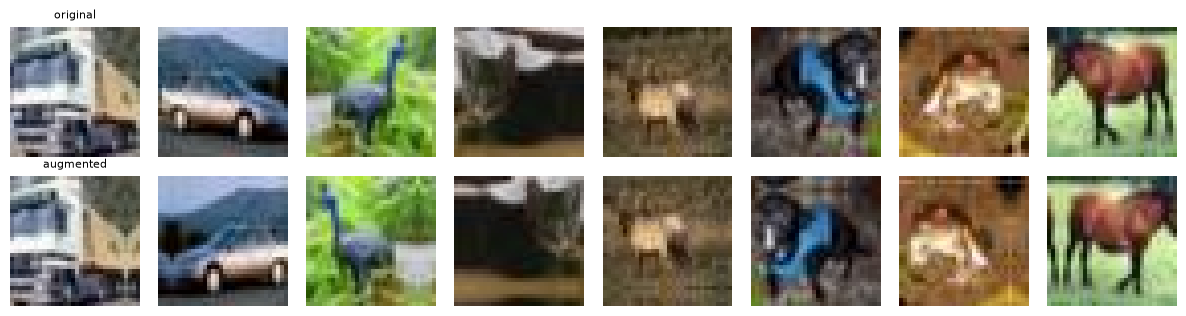

In [28]:
# TODO: 任务4.2 - 实现随机裁剪 + 水平翻转
def random_crop_flip(x, pad=4):
    """
    Args:
        x: torch.Tensor, shape [B, 3, 32, 32]
    Returns:
        torch.Tensor, shape [B, 3, 32, 32]

    提示：
    1. F.pad(x, (pad, pad, pad, pad), mode="reflect") 得到 [B, 3, 32+2pad, 32+2pad]
    2. 每个样本随机一个左上角 (dy, dx) ∈ [0, 2pad]，裁出 32×32
    3. 以 0.5 的概率对样本做 .flip(-1)
    """
    # ========== 开始编写代码 ==========
    padded = F.pad(x, (pad, pad, pad, pad), mode="reflect")
    B = x.shape[0]
    res = torch.empty_like(x)

    for i in range(B):
        dx = torch.randint(0, 2 * pad + 1, (), device=x.device).item()
        dy = torch.randint(0, 2 * pad + 1, (), device=x.device).item()
        cut = padded[i][:, dx : dx + 32, dy : dy + 32]
        if torch.rand((), device=x.device) < 0.5:
            cut = cut.flip(-1)
        res[i] = cut

    return res

    # ========== 结束编写代码 ==========
    pass

# 测试
xb = T_tr[:8]
aug = random_crop_flip(xb)
print(f"输出 shape: {tuple(aug.shape)}（应与输入一致 {tuple(xb.shape)}）")
same_or_flipped = all(torch.equal(a, b) or torch.equal(a, b.flip(-1)) for a, b in zip(random_crop_flip(xb, pad=0), xb))
print(f"pad=0 时输出等于原图或其水平翻转: {same_or_flipped}")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for col in range(8):
    for row, img in enumerate((xb[col], aug[col])):
        axes[row, col].imshow(((img * STD[0] + MEAN[0]).clamp(0, 1)).permute(1, 2, 0).cpu())
        axes[row, col].set_axis_off()
axes[0, 0].set_title("original", fontsize=8); axes[1, 0].set_title("augmented", fontsize=8)
savefig("augmentation")

### 任务4.3：优化与正则化

使用同一 CNN 结构进行三组实验：

1. 基线：不使用 BatchNorm、dropout 与数据增强，优化器为 AdamW。
2. 更换优化器：其余设置同基线，改用 SGD + momentum，学习率为 0.05。
3. 加入正则化：使用 BatchNorm、dropout 0.3 与数据增强，优化器为 AdamW。

epoch  1  train loss 0.3869  val loss 0.3986  train acc 0.8195  val acc 0.8086
epoch  2  train loss 0.4062  val loss 0.3980  train acc 0.8263  val acc 0.8294
epoch  3  train loss 0.1793  val loss 0.1895  train acc 0.9289  val acc 0.9264
epoch  4  train loss 0.1473  val loss 0.1559  train acc 0.9426  val acc 0.9390
epoch  5  train loss 0.1569  val loss 0.1731  train acc 0.9365  val acc 0.9330
epoch  6  train loss 0.1066  val loss 0.1377  train acc 0.9595  val acc 0.9472
epoch  7  train loss 0.0837  val loss 0.1285  train acc 0.9689  val acc 0.9516
epoch  8  train loss 0.0697  val loss 0.1242  train acc 0.9742  val acc 0.9546
epoch  9  train loss 0.0580  val loss 0.1186  train acc 0.9797  val acc 0.9560
epoch 10  train loss 0.0561  val loss 0.1176  train acc 0.9806  val acc 0.9570
[Part 4/classification] CNN baseline (AdamW): test_accuracy = 0.9539  (18s)
epoch  1  train loss 0.3155  val loss 0.3151  train acc 0.8645  val acc 0.8696
epoch  2  train loss 0.1940  val loss 0.1930  train acc

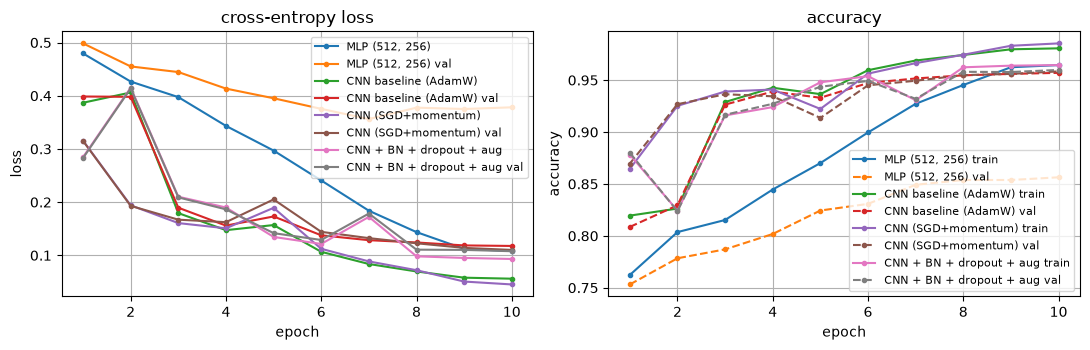

In [29]:
cnn_histories = {}
cnn_histories["CNN baseline (AdamW)"] = run_experiment("Part 4", "CNN baseline (AdamW)", CNN())
cnn_histories["CNN (SGD+momentum)"] = run_experiment("Part 4", "CNN (SGD + momentum, lr=0.05)", CNN(), optimizer="sgd", lr=0.05)
cnn_histories["CNN + BN + dropout + aug"] = run_experiment("Part 4", "CNN + BatchNorm + dropout + augmentation", CNN(use_bn=True, dropout=0.3), augment=random_crop_flip)
plot_histories({"MLP (512, 256)": h_mlp, **cnn_histories}, "cnn_curves")

## Part 5: 结果汇总与分析

### 汇总表与阶梯图

task               method                                           metric                      value      sec
----------------------------------------------------------------------------------------------------------------

[classification]
linear SVM (raw pixels)                          test_accuracy              0.6610      1.2
PCA-100 + RFF-8192 + linear SVM (~ RBF SVM)      test_accuracy              0.7847      2.0
MLP (256,)                                       test_accuracy              0.8351      3.4
MLP (512, 256)                                   test_accuracy              0.8563      3.8
MLP (1024, 512, 256)                             test_accuracy              0.8565      4.6
CNN baseline (AdamW)                             test_accuracy              0.9539     18.1
CNN (SGD + momentum, lr=0.05)                    test_accuracy              0.9564     17.8
CNN + BatchNorm + dropout + augmentation         test_accuracy              0.9608    263.6

[clustering]
2-means 

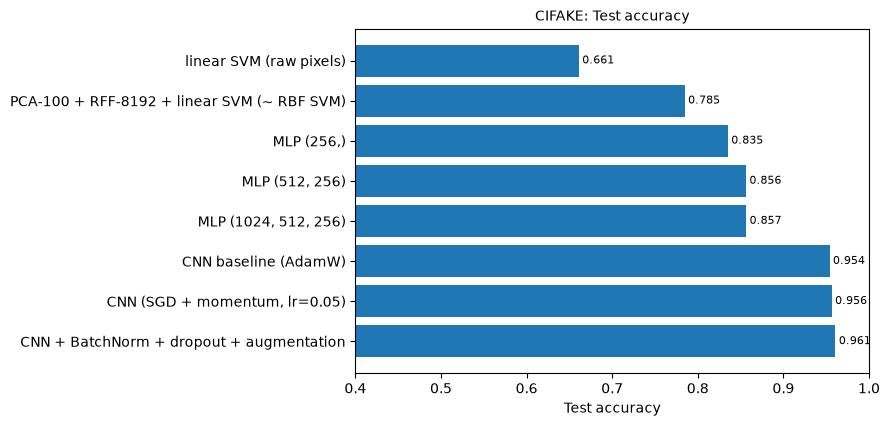

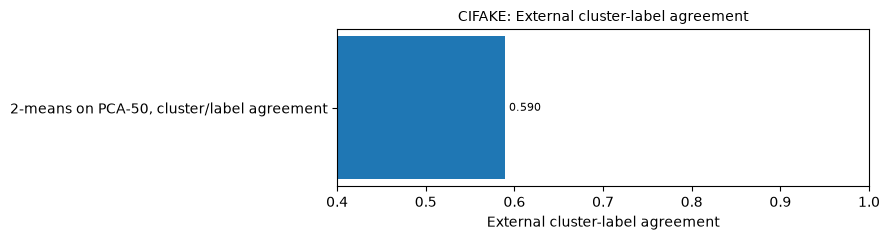

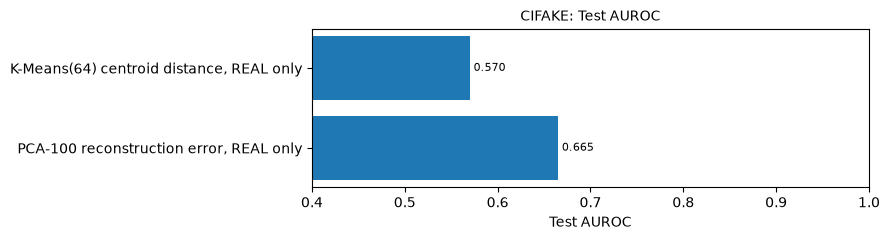

In [30]:
print(f"{'task':18s} {'method':48s} {'metric':24s} {'value':>8s} {'sec':>8s}")
print("-" * 112)
for task in ("classification", "clustering", "anomaly_detection"):
    print(f"\n[{task}]")
    for r in results:
        if r["task"] == task:
            print(f"{r['method']:48s} {r['metric']:24s} {r['value']:8.4f} {r['seconds']:8.1f}")

with open(OUT_DIR / "results.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(results[0].keys()))
    writer.writeheader()
    writer.writerows(results)
print(f"\n已保存到 {OUT_DIR / 'results.csv'}")

print("\nPart 4 generalization gaps (best validation-accuracy epoch)")
for name, h in cnn_histories.items():
    best = max(range(len(h["val_acc"])), key=h["val_acc"].__getitem__)
    gap = h["train_acc"][best] - h["val_acc"][best]
    print(f"{name}: epoch {best + 1}, train acc {h['train_acc'][best]:.4f}, val acc {h['val_acc'][best]:.4f}, gap {gap:.4f}")

plot_specs = [
    ("classification", "classification_accuracy", "Test accuracy"),
    ("clustering", "cluster_agreement", "External cluster-label agreement"),
    ("anomaly_detection", "anomaly_auroc", "Test AUROC"),
]
for task, filename, title in plot_specs:
    rows = [r for r in results if r["task"] == task]
    fig, ax = plt.subplots(figsize=(9, max(2.5, 0.42 * len(rows) + 1)))
    ax.barh([r["method"] for r in rows], [r["value"] for r in rows])
    ax.set_xlim(0.4, 1.0)
    ax.set_xlabel(title)
    ax.set_title(f"CIFAKE: {title}", fontsize=10)
    ax.invert_yaxis()
    for i, r in enumerate(rows):
        ax.text(r["value"] + 0.004, i, f"{r['value']:.3f}", va="center", fontsize=8)
    savefig(filename)

### 问题分析

请结合实验结果回答以下问题，每题三到五句。

**问题 1.** 线性 SVM 在原始像素上效果较差，而使用 RFF 近似 RBF 核后准确率明显提高，原因是什么？RFF 的维度 $D$ 与参数 $\gamma$ 分别如何影响结果？可补充实验加以说明。

**回答：**
原始像素中的真假差异难以用线性边界表达，PCA＋RFF 近似 RBF 核后可表示非线性关系，准确率由 66.10% 升至 78.47%。增大 $D$ 通常改善核近似，但增加计算量且不保证准确率持续提高。$\gamma$ 过大时模型过于局部、可能过拟合，过小时边界过于平滑、可能欠拟合。


**问题 2.** $K=2$ 的 K-Means 无法区分真实照片与生成图像。请结合任务 2.2 的簇样本与 PCA 散点图，说明聚类实际依据什么划分图片，并分析这反映了无监督学习的何种局限。

**回答：**
簇样本更像按整体明暗和背景色调分组，两簇均混有真假图片。前两个主成分的散点中两类大量重叠，簇标签与真伪标签的一致率仅为 58.99%。K-Means 优化特征距离，缺少真假标签指导，因此外观相似性形成的簇不一定对应目标类别。


**问题 3.** 仅用真实照片训练的异常检测器，其 AUROC 是否高于随机基线 0.5？这说明了什么？为什么 PCA 重构误差比 K-Means 中心距离更为有效？分类模型使用准确率报告，不能与 AUROC 做数值排名。

**回答：**
中心距离和重构误差的 AUROC 分别为 0.5701、0.6652，均高于 0.5，说明仅学习真实图片也能提供一定的真假排序信息。中心距离只利用保留的 PCA 特征，而重构误差反映偏离真实图像主子空间的残差，这可能解释后者更有效。AUROC 衡量排序能力，不能与分类准确率直接按数值排名。


**问题 4.** `CNN()` 的参数量少于 `MLP((512, 256))`，准确率却高出许多。请从归纳偏置（局部性、权值共享、平移等变性）的角度加以解释。

**回答：**
CNN 的局部连接适合提取边缘和纹理，权值共享使同一特征检测器能够在不同位置复用。卷积的平移等变性使特征响应随位置移动，配合池化提高对小位移的鲁棒性。CNN 以 618,306 个参数达到 95.39% 准确率，优于 MLP 的 1,705,218 个参数和 85.63%，体现了适合图像的结构先验的优势。


**问题 5.** 对比 Part 4 的三组实验，分别分析训练/验证损失曲线和训练/验证准确率曲线。在验证准确率最高的 epoch，计算训练准确率与验证准确率的差值，哪一组的泛化差距最小？原因是什么？

**回答：**
三组均设置了 `weight_decay=5e-4`，最佳验证轮均为第 10 轮，具体配置及训练减验证准确率的差值如下。

| 组别 | 配置 | 泛化差距 |
|---|---|---:|
| AdamW 基线 CNN | 不启用 BN、dropout 和数据增强 | 2.36 个百分点 |
| SGD＋momentum CNN | 其余同基线，学习率为 0.05 | 2.70 个百分点 |
| AdamW＋BN＋dropout＋增强 CNN | 启用 BN、dropout=0.3、随机裁剪与翻转 | 0.47 个百分点 |

三组训练和验证损失整体下降、准确率上升，前两组后期训练与验证的差距更明显。第三组训练损失较高、验证损失最低且泛化差距最小；其中 BatchNorm 是归一化操作，dropout 和数据增强用于抑制过拟合。
